%pip install numpy

In [1]:
import os
import torch
import xml.etree.ElementTree as ET
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

import torchvision
from torchvision.transforms import functional as F
from torch.utils.data import Dataset, DataLoader

## **Make Classes**

In [2]:
CLASSES = {
    "with_mask": 1,
    "without_mask": 2,
    "mask_weared_incorrect": 3
}

## **Parse XML**

In [3]:
def parse_xml(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    boxes = []
    labels = []

    for obj in root.findall("object"):
        label = obj.find("name").text
        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        boxes.append([xmin, ymin, xmax, ymax])
        labels.append(CLASSES[label])

    return boxes, labels

## **Create Dataset**

In [4]:
class FaceMaskDataset(Dataset):
    def __init__(self, img_dir, ann_dir):
        self.img_dir = img_dir
        self.ann_dir = ann_dir
        self.images = [f for f in os.listdir(img_dir) if f.endswith(".png")]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]

        img_path = os.path.join(self.img_dir, img_name)
        ann_path = os.path.join(self.ann_dir, img_name.replace(".png", ".xml"))

        image = Image.open(img_path).convert("RGB")

        boxes, labels = parse_xml(ann_path)

        boxes = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        image = F.to_tensor(image)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        return image, target

In [5]:
def collate_fn(batch):
    return tuple(zip(*batch))

## **Load Data**

In [ ]:
from torch.utils.data import DataLoader
BASE_DIR = "/Users/faizd/Github/Face-Mask-Detection/archive"

IMG_DIR = f"{BASE_DIR}/images"
ANN_DIR = f"{BASE_DIR}/annotations"

dataset = FaceMaskDataset(IMG_DIR, ANN_DIR)
def my_collate_fn(batch):
    return tuple(zip(*batch))
dataloader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    collate_fn=my_collate_fn
)

##  **Intialize Model**

In [7]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn


device = torch.device("cpu")
print("🔄 Reverting to stable CPU mode...")


model = fasterrcnn_resnet50_fpn(weights="DEFAULT")
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
    in_features,
    num_classes=4
)


model = model.to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
print("✅ Done! Model and Optimizer are ready on CPU.")


🔄 Reverting to stable CPU mode...
✅ Done! Model and Optimizer are ready on CPU.


## **Run Model on GPU**

In [8]:

#from torchvision.models.detection import fasterrcnn_resnet50_fpn

#model = fasterrcnn_resnet50_fpn(weights="DEFAULT")

#in_features = model.roi_heads.box_predictor.cls_score.in_features

#model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
 #   in_features,
  #  num_classes=4
#)
#model = model.to(device)

## **Set Optimizer**

In [9]:
params = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.SGD(
    params,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

##  **Training Loop**

In [10]:
try:
    print("Testing dataset image loading...")
    sample_img, sample_target = dataset[0]
    print("🚀 Success! Image shape:", sample_img.shape)
    print("Target labels:", sample_target)
except Exception as e:
    print("❌ Dataset failed to load!")
    print(f"Error Type: {type(e).__name__}")
    print(f"Error Message: {e}")

Testing dataset image loading...
🚀 Success! Image shape: torch.Size([3, 317, 600])
Target labels: {'boxes': tensor([[  9., 170.,  60., 229.],
        [165.,  90., 202., 124.],
        [175., 175., 244., 260.],
        [303., 127., 360., 191.],
        [340.,  66., 380., 111.],
        [379.,  63., 408.,  98.],
        [433.,  61., 471., 105.],
        [477.,  78., 536., 133.],
        [569.,  37., 592.,  67.],
        [367., 192., 437., 259.],
        [221.,  57., 248.,  81.]]), 'labels': tensor([1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 2]), 'image_id': tensor([0])}


In [11]:
from tqdm import tqdm
import torch


epochs = 1

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, targets in tqdm(dataloader, desc=f"Epoch {epoch+1}/{epochs}"):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]


        if device.type == "mps":
            torch.mps.synchronize()

        loss_dict = model(images, targets)
        loss = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} Finished. Total Loss: {total_loss:.4f}")


Epoch 1/1: 100%|██████████| 214/214 [45:02<00:00, 12.63s/it]

Epoch 1 Finished. Total Loss: 88.2283


## **Predict**

In [12]:
def predict(img_path):
    model.eval()

    image = Image.open(img_path).convert("RGB")
    img_tensor = F.to_tensor(image).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(img_tensor)[0]

    return image, pred

## **Show Image**

In [13]:
def show(image, pred, threshold=0.5):
    img = np.array(image)

    plt.figure(figsize=(10, 8))
    plt.imshow(img)

    for box, score, label in zip(
        pred["boxes"],
        pred["scores"],
        pred["labels"]
    ):
        if score < threshold:
            continue

        x1, y1, x2, y2 = box.cpu().numpy()

        plt.gca().add_patch(
            plt.Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="red",
                linewidth=2
            )
        )

        plt.text(x1, y1, f"{label.item()} {score:.2f}",
                 color="white",
                 bbox=dict(facecolor="red"))

    plt.axis("off")
    plt.show()

## **Test Image**

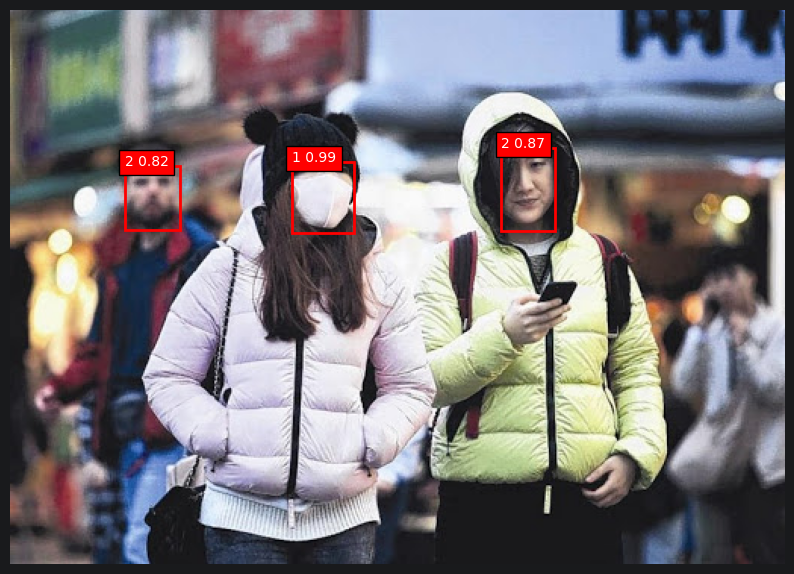

In [14]:
img_path = f"{IMG_DIR}/maksssksksss0.png"

image, pred = predict(img_path)
show(image, pred)